# SLIDE 1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

mat = pd.read_csv("student-mat.csv", sep=";")
por = pd.read_csv("student-por.csv", sep=";")
df = pd.concat([mat, por], ignore_index=True)

## Câu 1. Điểm trung bình G1, G2, G3 thay đổi thế nào giữa các kỳ?

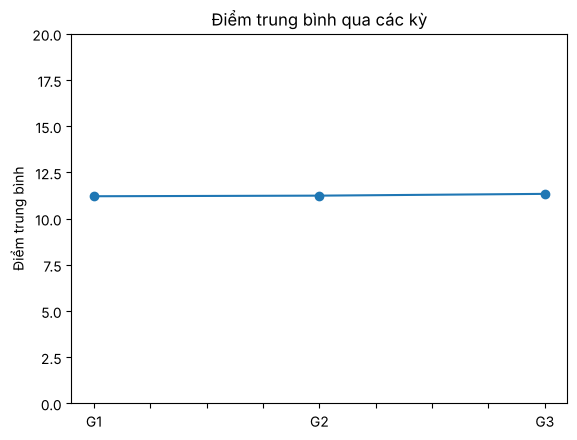

G1    11.213602
G2    11.246169
G3    11.341954
dtype: float64


In [2]:
tb = df[["G1", "G2", "G3"]].mean()
tb.plot(marker="o")
plt.ylim(0, 20)      # để trục y từ 0 đến 20 cho thấy đúng mức thay đổi
plt.title("Điểm trung bình qua các kỳ")
plt.ylabel("Điểm trung bình")
plt.show()
print(tb)

## Câu 2. Điểm trung bình của nam và nữ qua các kỳ

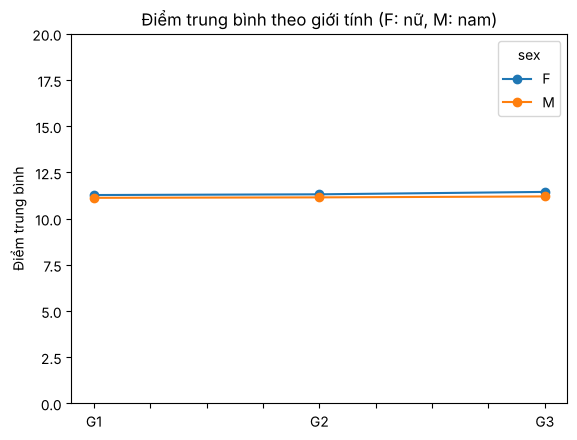

            G1         G2         G3
sex                                 
F    11.279188  11.318105  11.448393
M    11.128035  11.152318  11.203091


In [3]:
theo_gioi = df.groupby("sex")[["G1", "G2", "G3"]].mean()
theo_gioi.T.plot(marker="o")      # .T để mỗi giới tính là một đường
plt.ylim(0, 20)
plt.title("Điểm trung bình theo giới tính (F: nữ, M: nam)")
plt.ylabel("Điểm trung bình")
plt.show()
print(theo_gioi)

## Câu 3. Thời gian học trung bình theo nhóm tuổi

Dữ liệu không có cột "ngày trong tuần" nên dùng nhóm tuổi. Tuổi từ 19 trở lên rất ít nên gộp lại thành 19.

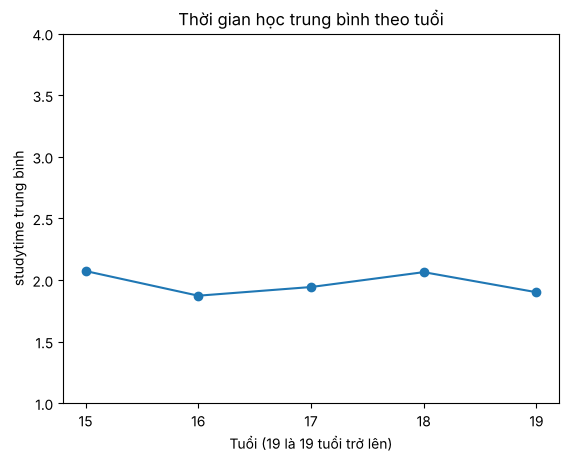

nhom_tuoi
15    2.072165
16    1.871886
17    1.942238
18    2.063063
19    1.900000
Name: studytime, dtype: float64


In [4]:
df["nhom_tuoi"] = df["age"].clip(upper=19)
st = df.groupby("nhom_tuoi")["studytime"].mean()
st.plot(marker="o")
plt.ylim(1, 4)       # studytime có mức từ 1 đến 4
plt.xticks([15, 16, 17, 18, 19])
plt.title("Thời gian học trung bình theo tuổi")
plt.xlabel("Tuổi (19 là 19 tuổi trở lên)")
plt.ylabel("studytime trung bình")
plt.show()
print(st)

## Câu 4. G3 trung bình theo giới tính và theo trường

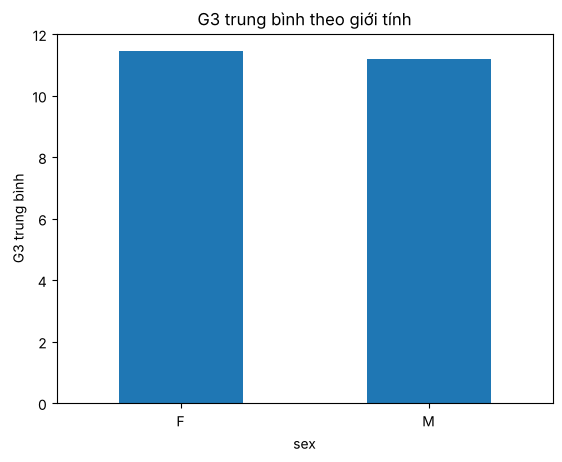

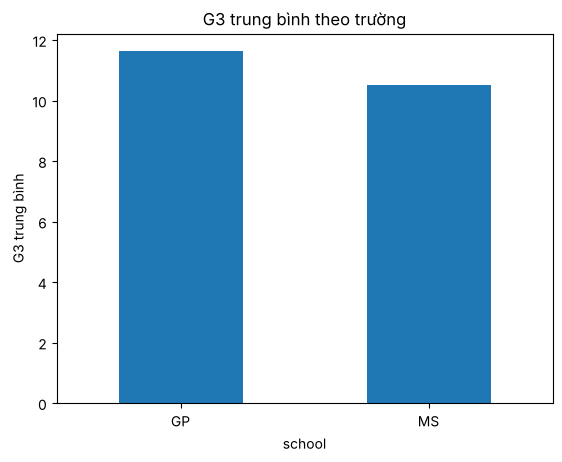

sex
F    11.448393
M    11.203091
Name: G3, dtype: float64
school
GP    11.633420
MS    10.514706
Name: G3, dtype: float64


In [5]:
df.groupby("sex")["G3"].mean().plot.bar()
plt.xticks(rotation=0)
plt.title("G3 trung bình theo giới tính")
plt.ylabel("G3 trung bình")
plt.show()

df.groupby("school")["G3"].mean().plot.bar()
plt.xticks(rotation=0)
plt.title("G3 trung bình theo trường")
plt.ylabel("G3 trung bình")
plt.show()

print(df.groupby("sex")["G3"].mean())
print(df.groupby("school")["G3"].mean())

## Câu 5. Đô thị (U) và nông thôn (R): điểm trung bình có khác nhau không?

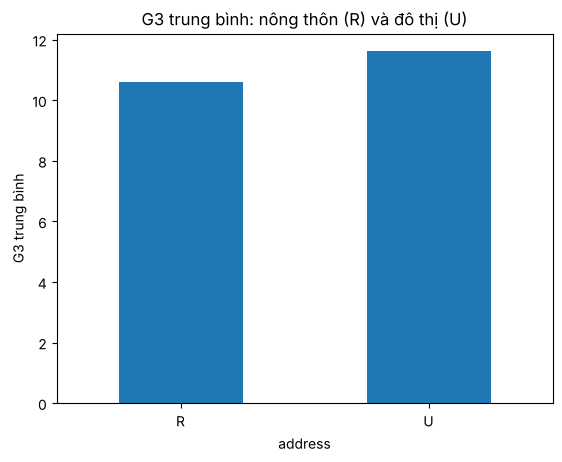

address
R    10.600000
U    11.620553
Name: G3, dtype: float64


In [6]:
df.groupby("address")["G3"].mean().plot.bar()
plt.xticks(rotation=0)
plt.title("G3 trung bình: nông thôn (R) và đô thị (U)")
plt.ylabel("G3 trung bình")
plt.show()

print(df.groupby("address")["G3"].mean())

## Câu 6. Ảnh hưởng của Internet ở nhà tới G3

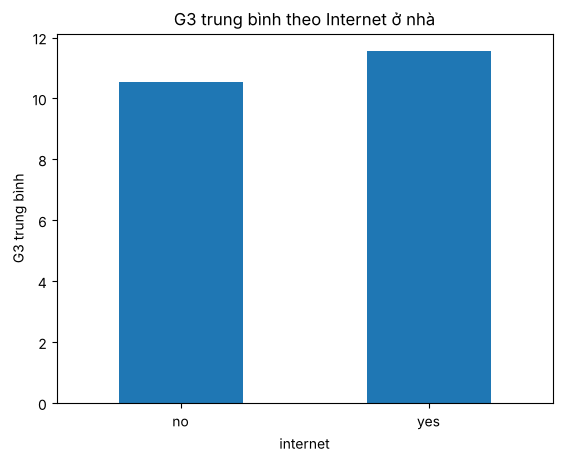

internet
no     10.534562
yes    11.553809
Name: G3, dtype: float64


In [7]:
df.groupby("internet")["G3"].mean().plot.bar()
plt.xticks(rotation=0)
plt.title("G3 trung bình theo Internet ở nhà")
plt.ylabel("G3 trung bình")
plt.show()

print(df.groupby("internet")["G3"].mean())

## Câu 7. Số học sinh theo tình trạng học thêm (schoolsup = yes/no)

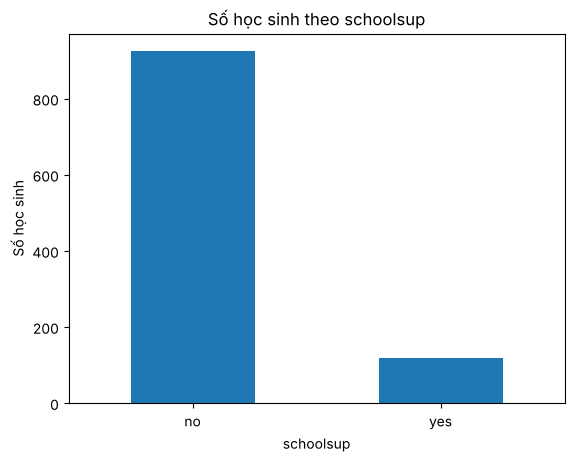

schoolsup
no     925
yes    119
Name: count, dtype: int64


In [8]:
df["schoolsup"].value_counts().plot.bar()
plt.xticks(rotation=0)
plt.title("Số học sinh theo schoolsup")
plt.ylabel("Số học sinh")
plt.show()

print(df["schoolsup"].value_counts())